In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, accuracy_score, roc_curve, auc, classification_report
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Загружаем данные 
df = pd.read_csv("data/processed_train_data.csv")

# Проверяем столбцы и выбираем бинарный признак для классификации
print("Доступные столбцы:", df.columns.tolist())
print("\nРаспределение Transmission_Manual:")
print(df['Transmission_Manual'].value_counts(normalize=True))

Доступные столбцы: ['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats', 'Price', 'Location_Bangalore', 'Location_Chennai', 'Location_Coimbatore', 'Location_Delhi', 'Location_Hyderabad', 'Location_Jaipur', 'Location_Kochi', 'Location_Kolkata', 'Location_Mumbai', 'Location_Pune', 'Fuel_Type_Diesel', 'Fuel_Type_Electric', 'Fuel_Type_LPG', 'Fuel_Type_Petrol', 'Transmission_Manual', 'Owner_Type_Fourth & Above', 'Owner_Type_Second', 'Owner_Type_Third']

Распределение Transmission_Manual:
Transmission_Manual
True     0.714238
False    0.285762
Name: proportion, dtype: float64


In [4]:
# Разделяем датасет на обучающую и тестовую выборки (60/40)
# random_state=42 фиксирует результат для воспроизводимости
X_train, X_test, y_train, y_test = train_test_split(
    df.drop('Price', axis=1), 
    df['Price'], 
    test_size=0.4, 
    random_state=42
)

# Решаем задачу регрессии для одного непрерывного признака 'Year'
# [[ ]], чтобы сохранить формат DataFrame
feature_name = 'Year'
X_train_single = X_train[[feature_name]]
X_test_single = X_test[[feature_name]]

# Создаем и обучаем дерево решений для регрессии
dt_regressor = DecisionTreeRegressor(random_state=42)
dt_regressor.fit(X_train_single, y_train)

# Делаем предсказания на тестовой выборке
y_pred_test = dt_regressor.predict(X_test_single)

# Оцениваем работу модели метриками из методички
mse = mean_squared_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred_test)

print(f"Модель: Дерево решений (признак: '{feature_name}')")
print("-" * 50)
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAE:  {mae:.2f}")
print("\nАнализ: Ошибки велики, так как модель использует только год выпуска.")
print("Для улучшения можно использовать все признаки или ограничить глубину дерева.")

Модель: Дерево решений (признак: 'Year')
--------------------------------------------------
MSE:  108.07
RMSE: 10.40
MAE:  6.76

Анализ: Ошибки велики, так как модель использует только год выпуска.
Для улучшения можно использовать все признаки или ограничить глубину дерева.


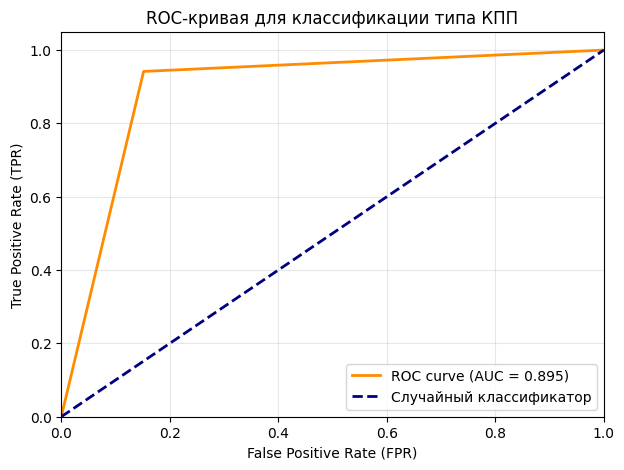

Площадь под ROC-кривой (AUC): 0.895

Интерпретация:
Хорошее качество разделения классов.


In [6]:
# Подготовка данных для классификации
# Убираем Price (целевая переменная регрессии) и сам Transmission_Manual из признаков
X_clf = df.drop(['Price', 'Transmission_Manual'], axis=1)
y_clf = df['Transmission_Manual']

# Разделяем на обучающую и тестовую выборки (60/40)
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.4, random_state=42
)

# Обучение дерева решений для классификации
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_classifier.fit(X_train_clf, y_train_clf)

# Получаем вероятности принадлежности к классу 1 (Manual)
# predict_proba возвращает массив [вероятность_0, вероятность_1], берем второй столбец
y_proba = dt_classifier.predict_proba(X_test_clf)[:, 1]

# Строим ROC-кривую 
fpr, tpr, thresholds = roc_curve(y_test_clf, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Случайный классификатор')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC-кривая для классификации типа КПП')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

print(f"Площадь под ROC-кривой (AUC): {roc_auc:.3f}")
print("\nИнтерпретация:")
if roc_auc > 0.9:
    print("Отличное качество разделения классов.")
elif roc_auc > 0.8:
    print("Хорошее качество разделения классов.")
else:
    print("Приемлемое или слабое качество.")